# Part C — The two-map activity, on real readers (9 marks)

`county_crime.csv` holds 20 counties with `crimes_reported` and `population`. **Same boundaries, same five-class scheme (Jenks natural breaks), same blue ramp — the only thing that changes is the denominator.**

| Step | Marks | Status in this notebook |
|---|---|---|
| 1 · Build both maps | 3 | ✅ fully automated below → `figures/partC_mapA_counts.png`, `partC_mapB_rates.png`, `partC_maps.png` |
| 2 · Run it on ≥ 5 real readers | 4 | ⚠️ **needs real people.** I did not invent any readers — the CSV template is empty until you fill it |
| 3 · Report mean overlap + what each map is a map of | 2 | ✅ code computes it the moment the CSV has ≥ 5 genuine rows; the "what each map is" sentences are written |

> The brief is explicit: fabricated or implausible reader results score **zero for the whole part**. So Step 2 is a protocol plus a results file you fill in, not numbers I made up.

In [1]:
import os, sys, json, itertools
sys.path.insert(0, os.getcwd())          # notebook sits beside vizlib.py / geolib.py
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import geolib as g                        # Week 5 toolkit (built on vizlib)
g.style_defaults()                        # Week 3 look, 300 dpi export default
DATA, FIG = "data/", "figures/"
os.makedirs(FIG, exist_ok=True)
PAL = g.PALETTE

def corr_chain(df, cols):
    """geolib.corr_chain with one line changed: newer pandas hands back a read-only
    array, so np.fill_diagonal on r.values raises. Same greedy rule (slide 24)."""
    cols = list(cols)
    r = df[cols].corr().abs()
    a = r.to_numpy().copy(); np.fill_diagonal(a, 0.0)
    r = pd.DataFrame(a, index=cols, columns=cols)
    i, j = np.unravel_index(np.argmax(a), a.shape)
    order = [cols[i], cols[j]]
    while len(order) < len(cols):
        rest = [c for c in cols if c not in order]
        order.append(max(rest, key=lambda c: r.loc[order[-1], c]))
    return order

NUM = ["gdp_pc", "healthcare_access", "urban_pct", "median_age", "cases_per_100k"]

cc = pd.read_csv(DATA + "county_crime.csv")
cc["rate"] = cc.crimes_reported / cc.population * 1e5
all_feats = g.read_geojson(DATA + "districts.geojson")

# join on code; the 20 counties are D01–D20, geometry carries D01–D24 -> four polygons will not match
geo_codes, tab_codes = {f["code"] for f in all_feats}, set(cc.code)
unmatched = sorted(geo_codes - tab_codes)
print("counties in file:", len(tab_codes), "| polygons in geojson:", len(geo_codes))
print("polygons with NO county row (left out of both maps):", unmatched)
print("county rows with no polygon:", sorted(tab_codes - geo_codes))
feats = [f for f in all_feats if f["code"] in tab_codes]
assert len(feats) == 20
name = dict(zip(cc.code, cc.county))

counties in file: 20 | polygons in geojson: 24
polygons with NO county row (left out of both maps): ['D21', 'D22', 'D23', 'D24']
county rows with no polygon: []


In [2]:
# ---- self-check numbers from the brief
print(f"r(crimes_reported, population) = {cc.crimes_reported.corr(cc.population):+.3f}   (brief: +0.935)")
cc["rank_count"] = cc.crimes_reported.rank(ascending=False, method="min").astype(int)
cc["rank_rate"] = cc.rate.rank(ascending=False, method="min").astype(int)
top_c = cc.nlargest(3, "crimes_reported").county.tolist()
top_r = cc.nlargest(3, "rate").county.tolist()
print("top 3 by COUNT:", top_c)
print("top 3 by RATE :", top_r, "| overlap =", len(set(top_c) & set(top_r)))
cc["places_moved"] = (cc.rank_count - cc.rank_rate).abs()
print(f"counties that move >= 3 places between the two rankings: {(cc.places_moved >= 3).sum()} of 20")
print(cc[cc.county.isin(["Elmsworth", "Hollowfield"])][["county", "population", "crimes_reported", "rate", "rank_count", "rank_rate"]].round(1).to_string(index=False))

r(crimes_reported, population) = +0.935   (brief: +0.935)
top 3 by COUNT: ['Dunmere', 'Pellbrook', 'Grimsby']
top 3 by RATE : ['Hollowfield', 'Netherby', 'Elmsworth'] | overlap = 0
counties that move >= 3 places between the two rankings: 7 of 20
     county  population  crimes_reported   rate  rank_count  rank_rate
  Elmsworth       22000              384 1745.5          13          3
Hollowfield       12000              216 1800.0          16          1


Map A class breaks: [88.0, 240.0, 840.0, 1952.0, 3038.0, 5971.0]
Map B class breaks: [479.0, 613.0, 794.0, 943.0, 1405.0, 1800.0]


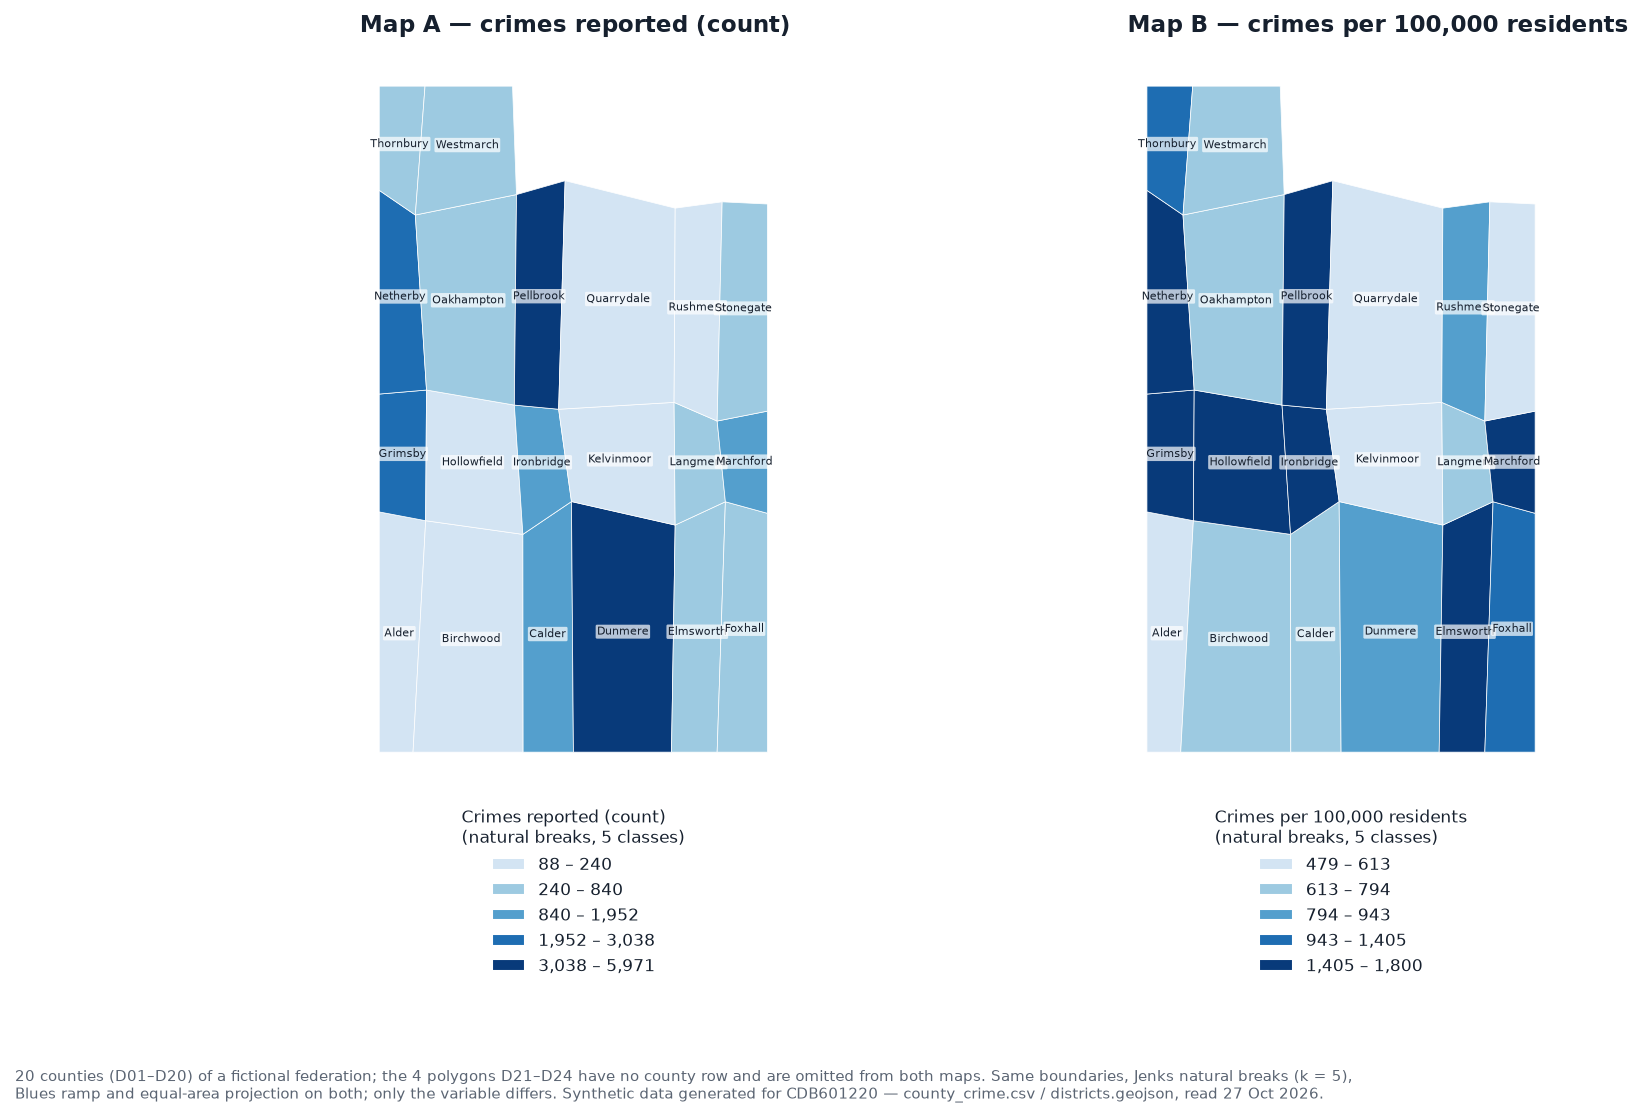

saved: partC_maps.png, partC_mapA_counts.png, partC_mapB_rates.png  (300 dpi)


In [3]:
# ---- both maps: identical boundaries, scheme, ramp, projection. ONLY the variable differs.
lat_ts = float(np.mean([p[1] for f in feats for p in f["ring"]]))
def label_counties(ax):
    for f in feats:
        px, py = g.representative_point(f["ring"])
        x, y = g.equal_area_xy([px], [py], lat_ts=lat_ts)           # same standard parallel as g.choropleth
        ax.text(x[0], y[0], name[f["code"]], ha="center", va="center", fontsize=5.4, color=PAL["ink"],
                bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.7), zorder=6)

def one_map(ax, values, title, legend_title, fmt):
    e = g.choropleth(ax, feats, dict(zip(cc.code, values)), scheme="natural", k=5,
                     legend_title=legend_title, fmt=fmt, legend_loc="upper center", legend_anchor=(0.5, -0.01))
    label_counties(ax); ax.set_title(title, loc="left", fontsize=11)
    return e

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 7.4)); fig.subplots_adjust(bottom=0.22, wspace=0.12)
eA = one_map(a1, cc.crimes_reported, "Map A — crimes reported (count)", "Crimes reported (count)\n(natural breaks, 5 classes)", "{:,.0f}")
eB = one_map(a2, cc.rate, "Map B — crimes per 100,000 residents", "Crimes per 100,000 residents\n(natural breaks, 5 classes)", "{:,.0f}")
print("Map A class breaks:", np.round(eA, 0).tolist()); print("Map B class breaks:", np.round(eB, 0).tolist())
note = ("20 counties (D01–D20) of a fictional federation; the 4 polygons D21–D24 have no county row and are omitted from both maps. "
        "Same boundaries, Jenks natural breaks (k = 5), Blues ramp and equal-area projection on both; only the variable differs. "
        "Synthetic data generated for CDB601220 — county_crime.csv / districts.geojson, read 27 Oct 2026.")
import textwrap
g.save_fig(fig, FIG + "partC_maps.png", note="\n".join(textwrap.wrap(note, 170)))
plt.show()

# separate files for showing readers ONE map at a time (protocol step 1 shows Map A alone)
for key, vals, ttl, lt, fm in [("mapA_counts", cc.crimes_reported, "Map A — crimes reported (count)", "Crimes reported (count)\n(natural breaks, 5 classes)", "{:,.0f}"),
                               ("mapB_rates", cc.rate, "Map B — crimes per 100,000 residents", "Crimes per 100,000 residents\n(natural breaks, 5 classes)", "{:,.0f}")]:
    f_, a_ = plt.subplots(figsize=(6.6, 7.4)); f_.subplots_adjust(bottom=0.22)
    one_map(a_, vals, ttl, lt, fm)
    g.save_fig(f_, FIG + f"partC_{key}.png", note="\n".join(textwrap.wrap(note, 95))); plt.close(f_)
print("saved: partC_maps.png, partC_mapA_counts.png, partC_mapB_rates.png  (300 dpi)")

## Step 2 · The reader protocol (do this with real people, then fill in the CSV)

Show **one reader at a time**, in this order:

1. Show them **only** `figures/partC_mapA_counts.png`. Ask: *"Which three counties would you send extra police to, and why?"* Write their three down.
2. Then show `figures/partC_mapB_rates.png` and ask the **same** question. Write their three down.
3. **Do not let them revise answer 1.**

Record one row per reader in **`partC_reader_results.csv`** with columns  
`reader_id, A_pick1, A_pick2, A_pick3, B_pick1, B_pick2, B_pick3` (county names exactly as spelled in the maps). The overlap count is computed below — don't type it.  
At least **five** readers; if they pick the same three from both maps, that is a result — report it and say what you think happened.

In [4]:
RES = "partC_reader_results.csv"
COLS = ["reader_id", "A_pick1", "A_pick2", "A_pick3", "B_pick1", "B_pick2", "B_pick3"]
if not os.path.exists(RES):
    pd.DataFrame(columns=COLS).to_csv(RES, index=False)              # empty template: header only, NO invented rows
    print(f"created empty template {RES} — fill it with your real readers, then re-run this cell")

R = pd.read_csv(RES)
valid = set(cc.county)
if len(R) == 0:
    print("partC_reader_results.csv has no rows yet -> nothing to analyse. (No reader data has been invented.)")
else:
    bad = [(i, col, v) for i, row in R.iterrows() for col in COLS[1:] if row[col] not in valid for v in [row[col]]]
    if bad: print("⚠️ picks that are not county names (check spelling):", bad)
    R["overlap"] = [len({r.A_pick1, r.A_pick2, r.A_pick3} & {r.B_pick1, r.B_pick2, r.B_pick3}) for r in R.itertuples()]
    print(R.to_string(index=False))
    if len(R) < 5:
        print(f"\nonly {len(R)} reader(s): the brief needs at least 5 real readers before this part can be reported.")
    else:
        print(f"\nn = {len(R)} readers | mean overlap between their A-picks and B-picks = {R.overlap.mean():.2f} of 3 "
              f"(min {R.overlap.min()}, max {R.overlap.max()})")
        pick_counts = pd.concat([R[["A_pick1", "A_pick2", "A_pick3"]].stack(), R[["B_pick1", "B_pick2", "B_pick3"]].stack()], keys=["A", "B"]).reset_index(level=0)
        print("\nmost-picked counties from Map A:", R[["A_pick1", "A_pick2", "A_pick3"]].stack().value_counts().head(3).to_dict())
        print("most-picked counties from Map B:", R[["B_pick1", "B_pick2", "B_pick3"]].stack().value_counts().head(3).to_dict())
        print(f"for reference — the data's own top-3 by count {top_c} and by rate {top_r} overlap by 0")

created empty template partC_reader_results.csv — fill it with your real readers, then re-run this cell
partC_reader_results.csv has no rows yet -> nothing to analyse. (No reader data has been invented.)


## Step 3 · What each map is actually a map of

* **Map A (counts)** is a **map of where the people are**: crimes reported track population almost one-for-one (r = **+0.935**), so the darkest counties are simply the biggest ones — Dunmere, Pellbrook and Grimsby. It tells a police chief nothing about risk *per resident*.
* **Map B (rates per 100,000)** is a **map of risk per resident**: it puts Hollowfield (12,000 people), Netherby and Elmsworth (22,000 people) at the top — Hollowfield and Elmsworth were only **16th and 13th of 20** by count (the lower end of the count map, the printed ranks above). The two top-three lists overlap by **zero**, and **7 of the 20 counties move three or more places** between the rankings.

**Caveat for the write-up (small counties):** Hollowfield and Elmsworth have 12,000 and 22,000 residents — exactly the size where a rate is noisy (Part B5's funnel plot). Map B is the right *denominator*, but those two rates still need a stability check before anyone is sent anywhere.

**Mean overlap across your readers:** run the cell above after filling in the CSV — it prints the number. State it, and one sentence on what you think happened if it is high (readers who see Map A first tend to anchor on their A-picks and ignore the change of denominator) or low (the denominator changed the decision).